# **Forecasting Energy Prices based on Production and Consumption with Variability Estimation through Monte Carlo Simulations**

The project aims to forecast electricity prices based on the variability of production factors and actual consumption. A Random Forest model is used to capture the relationship between temporal variables (e.g., time of day, day of the week as weekday vs. holiday, month), weather conditions, and production load assumptions.

An in-depth exploratory analysis of the variables has been carried out, followed by preprocessing activities aimed at correcting distribution distortions and managing outliers. Subsequently, feature selection has been performed using Pearson correlation analysis and the Variance Inflation Factor (VIF), with the goal of improving dataset quality by reducing redundancy and informational noise, thereby enhancing the model’s ability to learn meaningful patterns from the data.

**- Monte Carlo Simulation:**
The core of the project is a Monte Carlo simulation with 10,000 random scenarios, designed to estimate price variability in relation to different climatic and environmental conditions. The objective is to obtain a probabilistic distribution of energy prices under realistic scenarios, using the already trained model.

This stochastic approach provides a more realistic view of the variability of the factors influencing price determination and helps contain price fluctuations within limits consistent with historical trends, avoiding extreme volatility. The result is a robust predictive system capable of supporting strategic decisions in the energy market, while accounting for uncertainty related to environmental and demand factors.

**The dataset contains the information useful for forecasting:**

* DateTime: Date and time of the observation
* Holiday: Name of the holiday
* HolidayFlag: Contains 1 if it is a holiday, 0 otherwise
* DayOfWeek: Day of the week (0 is Monday)
* WeekOfYear: Week of the year
* Day: Day of the date
* Month: Month of the date
* Year: Year of the date
* PeriodOfDay: Period of the day (in half-hour intervals)
* ForcastWindProduction: Forecasted wind production
* SystemLoadEA: Forecasted national system load
* SMPEA: Forecasted price
* ORKTemperature: Actual measured temperature
* ORKWindspeed: Actual measured wind speed
* CO2Intensity: Actual CO₂ intensity for the produced energy
* ActualWindProduction: Actual wind energy production
* SystemLoadEP2: Actual national system load
* SMPEP2 (TARGET to predict): Actual price of consumed energy

In [ ]:
# Librerie
import pandas as pd
import numpy as np

# Visualizzazione
import seaborn as sns
import matplotlib.pyplot as plt

# EDA
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Transformations
from sklearn.preprocessing import PowerTransformer, StandardScaler

# Model
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR

# Evaluations
from sklearn.metrics import mean_squared_error, r2_score

# Model and feature selection engineering
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectFromModel

In [ ]:
data = pd.read_csv(
    "https://raw.githubusercontent.com/Valeria-Raele/energy-price-forecasting-monte-carlo/refs/heads/main/datasets/electricity.csv",
    low_memory=False
)
print(data.head())

           DateTime Holiday  HolidayFlag  DayOfWeek  WeekOfYear  Day  Month  \
0  01/11/2011 00:00     NaN            0          1          44    1     11   
1  01/11/2011 00:30     NaN            0          1          44    1     11   
2  01/11/2011 01:00     NaN            0          1          44    1     11   
3  01/11/2011 01:30     NaN            0          1          44    1     11   
4  01/11/2011 02:00     NaN            0          1          44    1     11   

   Year  PeriodOfDay ForecastWindProduction SystemLoadEA  SMPEA  \
0  2011            0                 315.31      3388.77  49.26   
1  2011            1                 321.80      3196.66  49.26   
2  2011            2                 328.57      3060.71  49.10   
3  2011            3                 335.60      2945.56  48.04   
4  2011            4                 342.90      2849.34  33.75   

  ORKTemperature ORKWindspeed CO2Intensity ActualWindProduction SystemLoadEP2  \
0           6.00         9.30       600.7

**EDA (Exploratory Data Analysis)**

In [ ]:
data.shape

(38014, 18)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38014 entries, 0 to 38013
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   DateTime                38014 non-null  object
 1   Holiday                 1536 non-null   object
 2   HolidayFlag             38014 non-null  int64 
 3   DayOfWeek               38014 non-null  int64 
 4   WeekOfYear              38014 non-null  int64 
 5   Day                     38014 non-null  int64 
 6   Month                   38014 non-null  int64 
 7   Year                    38014 non-null  int64 
 8   PeriodOfDay             38014 non-null  int64 
 9   ForecastWindProduction  38014 non-null  object
 10  SystemLoadEA            38014 non-null  object
 11  SMPEA                   38014 non-null  object
 12  ORKTemperature          38014 non-null  object
 13  ORKWindspeed            38014 non-null  object
 14  CO2Intensity            38014 non-null  object
 15  Ac

Many variables are observed to have numerical values stored as strings instead of integers or decimals. It is therefore necessary to convert these values from strings to float type.

In [ ]:
data["ForecastWindProduction"] = pd.to_numeric(data["ForecastWindProduction"], errors= 'coerce')
data["SystemLoadEA"] = pd.to_numeric(data["SystemLoadEA"], errors= 'coerce')
data["SMPEA"] = pd.to_numeric(data["SMPEA"], errors= 'coerce')
data["ORKTemperature"] = pd.to_numeric(data["ORKTemperature"], errors= 'coerce')
data["ORKWindspeed"] = pd.to_numeric(data["ORKWindspeed"], errors= 'coerce')
data["CO2Intensity"] = pd.to_numeric(data["CO2Intensity"], errors= 'coerce')
data["ActualWindProduction"] = pd.to_numeric(data["ActualWindProduction"], errors= 'coerce')
data["SystemLoadEP2"] = pd.to_numeric(data["SystemLoadEP2"], errors= 'coerce')
data["SMPEP2"] = pd.to_numeric(data["SMPEP2"], errors= 'coerce')

In [ ]:
# Check if the dataset contains null values
data.isnull().sum()

,0
DateTime,0
Holiday,36478
HolidayFlag,0
DayOfWeek,0
WeekOfYear,0
Day,0
Month,0
Year,0
PeriodOfDay,0
ForecastWindProduction,5


We remove the variable Holiday, which contains almost all null values, and Datetime, which is a complex object for machine learning models such as Linear Regression and duplicates the information already conveyed by the variables Year, Month, Day, and DayOfWeek.

In [ ]:
# We remove the "Holiday" and "DateTime" columns
data = data.drop(["Holiday", "DateTime"], axis=1)

In [ ]:
# Impute missing values with the median for numerical columns
data["ORKTemperature"] = data["ORKTemperature"].fillna(data["ORKTemperature"].median())
data["ORKWindspeed"] = data["ORKWindspeed"].fillna(data["ORKWindspeed"].median())
data["ForecastWindProduction"] = data["ForecastWindProduction"].fillna(data["ForecastWindProduction"].median())
data["SystemLoadEA"] = data["SystemLoadEA"].fillna(data["SystemLoadEA"].median())
data["SMPEA"] = data["SMPEA"].fillna(data["SMPEA"].median())
data["CO2Intensity"] = data["CO2Intensity"].fillna(data["CO2Intensity"].median())
data["ActualWindProduction"] = data["ActualWindProduction"].fillna(data["ActualWindProduction"].median())
data["SystemLoadEP2"] = data["SystemLoadEP2"].fillna(data["SystemLoadEP2"].median())
data["SMPEP2"] = data["SMPEP2"].fillna(data["SMPEP2"].median())

# Show the number of null values
data.isnull().sum()

,0
HolidayFlag,0
DayOfWeek,0
WeekOfYear,0
Day,0
Month,0
Year,0
PeriodOfDay,0
ForecastWindProduction,0
SystemLoadEA,0
SMPEA,0


UNIVARIATE ANALYSIS

In [ ]:
# Summarization
data.describe()

,HolidayFlag,DayOfWeek,WeekOfYear,Day,Month,Year,PeriodOfDay,ForecastWindProduction,SystemLoadEA,SMPEA,ORKTemperature,ORKWindspeed,CO2Intensity,ActualWindProduction,SystemLoadEP2,SMPEP2
count,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000,38014.000000
mean,0.040406,2.997317,28.124586,15.739412,6.904246,2012.383859,23.501105,544.247998,4020.089413,62.719994,9.621508,19.206171,479.373213,520.752854,3785.978038,64.136371
std,0.196912,1.999959,15.587575,8.804247,3.573696,0.624956,13.853108,414.339037,860.454442,32.251532,4.423014,9.533801,85.346848,378.259094,843.247470,35.414160
min,0.000000,0.000000,1.000000,1.000000,1.000000,2011.000000,0.000000,0.680000,2183.940000,0.000000,-4.000000,0.000000,0.000000,1.000000,1809.960000,-47.740000
25%,0.000000,1.000000,15.000000,8.000000,4.000000,2012.000000,12.000000,189.700000,3281.220000,45.530000,7.000000,13.000000,421.110000,199.000000,3058.285000,45.780000
50%,0.000000,3.000000,29.000000,16.000000,7.000000,2012.000000,24.000000,441.980000,4103.600000,55.230000,9.000000,18.500000,480.310000,445.000000,3865.745000,55.545000
75%,0.000000,5.000000,43.000000,23.000000,10.000000,2013.000000,35.750000,839.430000,4638.487500,70.320000,13.000000,24.100000,537.475000,793.000000,4427.572500,72.107500
max,1.000000,6.000000,52.000000,31.000000,12.000000,2013.000000,47.000000,1680.000000,6492.910000,587.580000,25.000000,75.900000,842.880000,1769.000000,6309.750000,1000.000000


Analysis on minimum, maximum, mean, standard deviation, and quartiles (25%, 50%, 75%).

---
TIME VARIABLES

| Variable       | Min | 25% | 50% | 75% | Max | Mean   |
|----------------|-----|-----|-----|-----|-----|--------|
| DayOfWeek      | 0   | 1   | 3   | 5   | 6   | 2,99   |
| WeekOfYear     | 1   | 15  | 29  | 43  | 52  | 28,12  |
| Day            | 1   | 8   | 16  | 23  | 31  | 15,74  |
| Month          | 1   | 4   | 7   | 10  | 12  | 6,9    |
| Year           |2011 |2012 |2012 |2013 |2013 | 2012   |
| PeriodOfDay    | 0   | 12  | 24  | 35  | 47  | 23,5   |

Observations appear to be normally distributed. No significant outliers are detected, but the variable scales differ.

---
BINARY VARIABLE

HolidayFlag: contains 1 if it is a holiday, 0 otherwise; Binary variable, therefore not subject to distribution observation.

---
CLIMATIC AND ENERGY PRODUCTION VARIABLES

| Variable           | Min   | 25%   | 50%   | 75%   | Max    | Mean | Observations |
|---------------------|--------|--------|--------|--------|--------|--------|--------------|
| ORKTemperature       | -4    | 7      | 9      | 13     | 25     | 9,62   | Normal distribution, no outliers |
| CO2Intensity         | 0     | 421,11 | 480,31 | 537,47 | 842,88 | 479,37 | Not normal, but no outliers |

---
VARIABLES WITH POSSIBLE OUTLIERS / SKEWED DISTRIBUTIONS

| Variable              | Min    | 25%    | 50%    | 75%    | Max     | Mean   | Note |
|-----------------------|--------|--------|--------|--------|---------|---------|------|
| ForecastWindProduction| 0,68   | 189,7  | 441,98 | 839,43 | 1680    | 544,25  | Outlier at maximum value |
| SystemLoadEA          | 2183,94| 3281,22| 4103,6 | 4638,49| 6492,91 | 40,09   | Maximum value high vs. mean |
| SMPEA                 | 0      | 45,53  | 55,23  | 70,32  | 587,58  | 62,72   | Outlier at maximum value |
| ORKWindspeed          | 0      | 13     | 18     | 24     | 75,9    | 19,21   | Outlier at maximum value |
| ActualWindProduction  | 1      | 199    | 445    | 793    | 1769    | 520,75  | Outlier at maximum value |
| SystemLoadEP2         | 1809,96| 3058,28| 3865,74| 4427,57| 6309,75 | 3785,98 | Skewed distribution |

---
TARGET VARIABLE

| Variable  | Min     | 25%   | 50%   | 75%   | Max  | Mean   | Note |
|-----------|---------|-------|-------|-------|------|--------|------|
| SMPEP2    | -47,74  | 45,78 | 55,54 | 72,10 | 1000 | 64,14  | Clear outlier at max, distribution with high extremes |


BOX PLOT

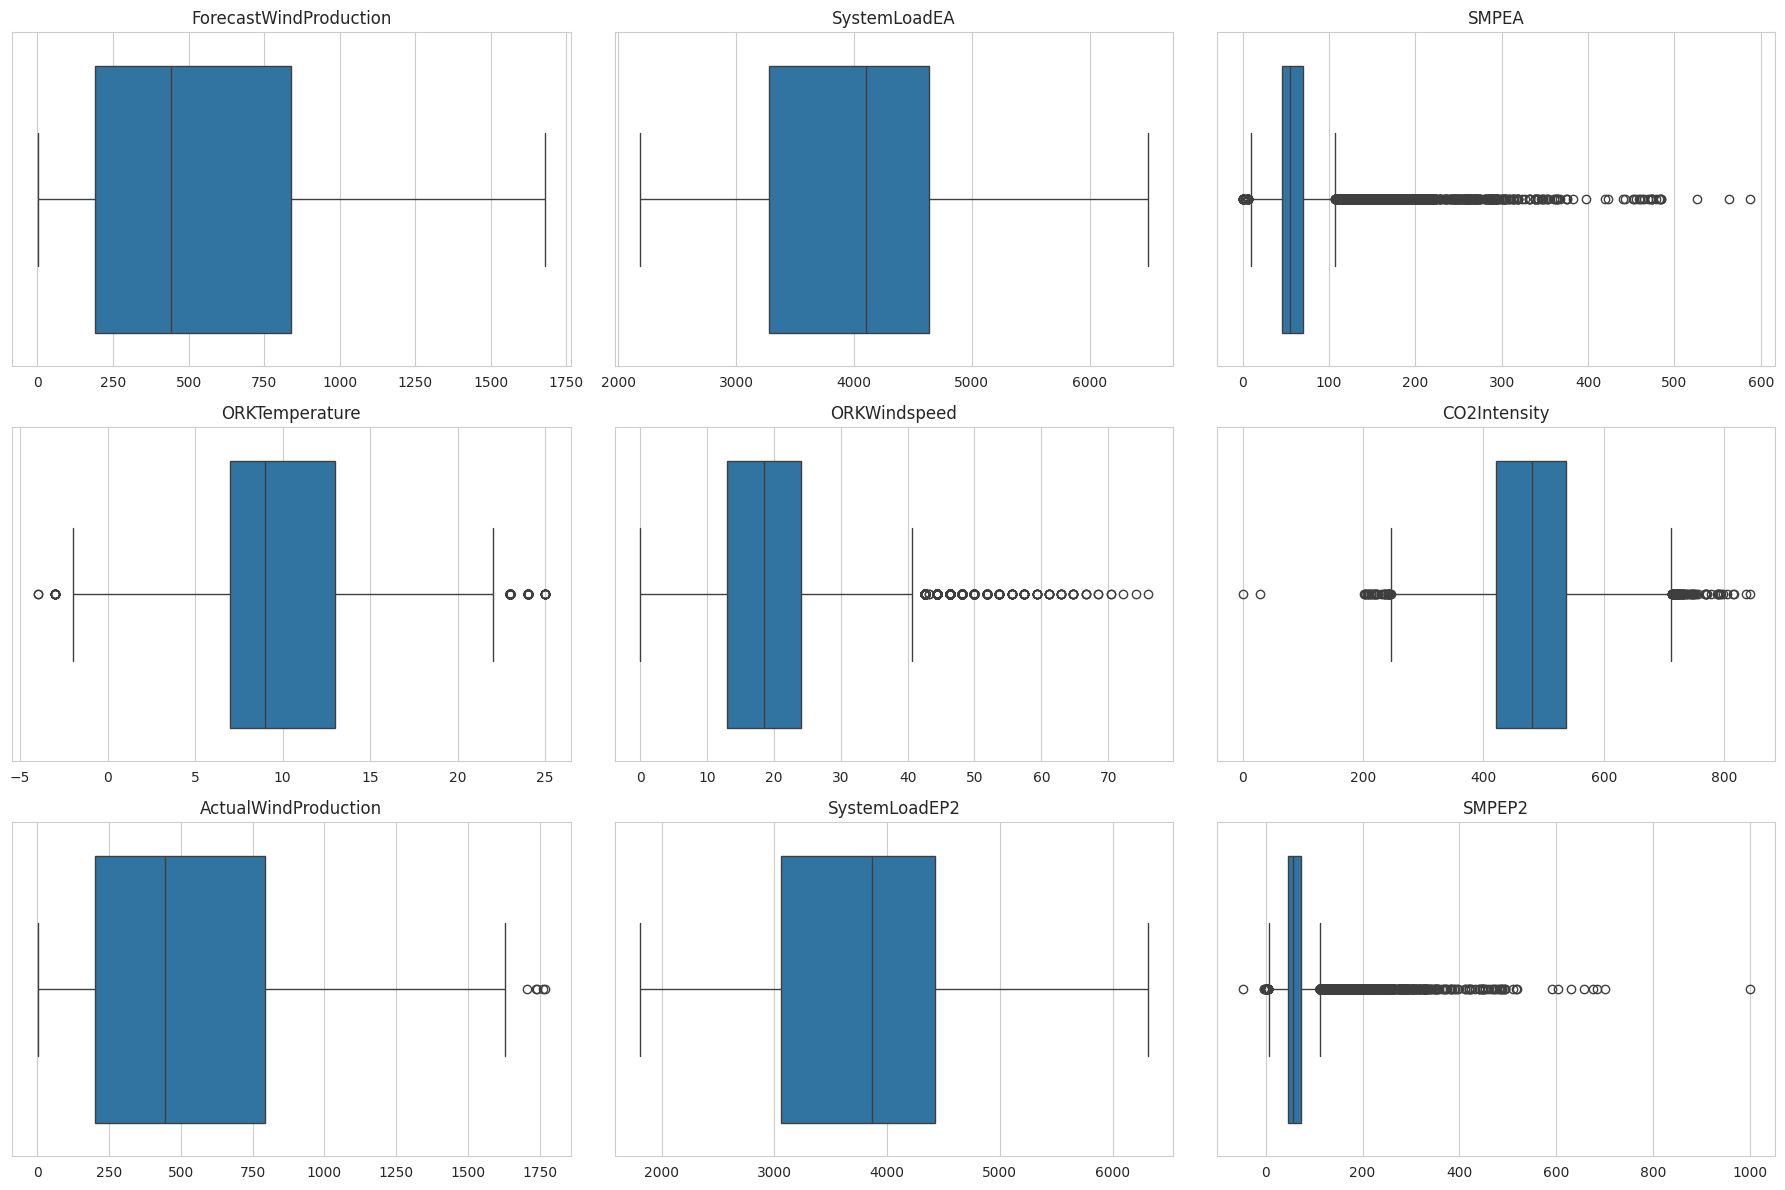

In [ ]:
# List of the 9 specified columns
cols_to_plot = [
    'ForecastWindProduction', 'SystemLoadEA', 'SMPEA',
    'ORKTemperature', 'ORKWindspeed', 'CO2Intensity',
    'ActualWindProduction', 'SystemLoadEP2', 'SMPEP2'
]

# Set up the figure with 3 rows and 3 columns
plt.figure(figsize=(18, 12))

# Create the boxplot for each variable
for i, col in enumerate(cols_to_plot):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(x=data[col])
    plt.title(col)
    plt.xlabel('')

# Improve the layout of the plots
plt.tight_layout()
plt.show()


* ForecastWindProduction, SystemLoadEA, and SystemLoadEP2: the distributions appear skewed, with the median slightly shifted relative to the mean. No outliers are present.
* ActualWindProduction and ORKTemperature: the distributions appear skewed, with the median slightly shifted relative to the mean. A few outliers are present.
* ORKWindSpeed, SMPEA, CO2Intensity, and SMPEP2: the distributions are fairly symmetric, with the median coinciding with the mean. The large presence of outliers represents a significant issue.

EVALUATING THE SHAPE OF THE DISTRIBUTIONS

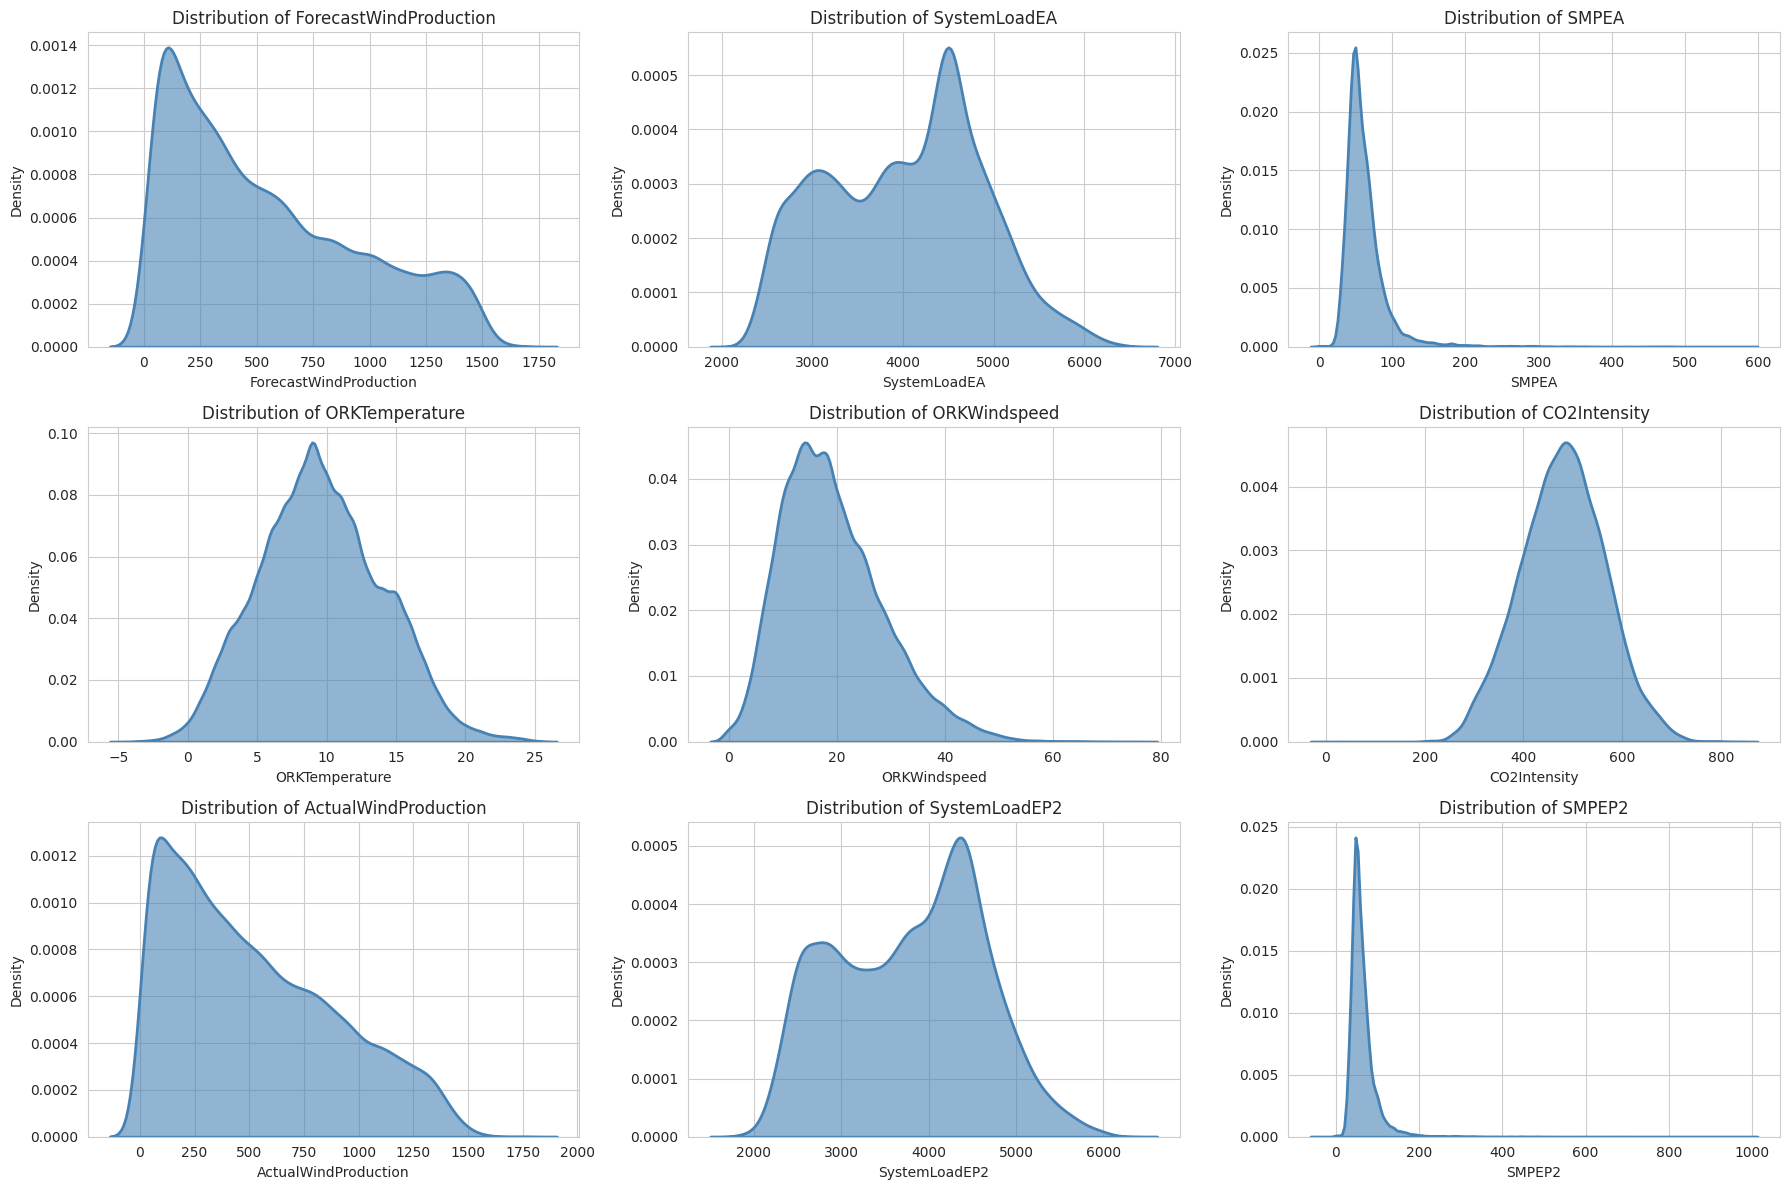

In [ ]:
# List of the 9 desired variables
cols_to_plot = [
    'ForecastWindProduction', 'SystemLoadEA', 'SMPEA',
    'ORKTemperature', 'ORKWindspeed', 'CO2Intensity',
    'ActualWindProduction', 'SystemLoadEP2', 'SMPEP2'
]

# Set style
sns.set_style("whitegrid")

# Set up 3 rows and 3 columns
plt.figure(figsize=(18, 12))

# Create KDE plots
for i, col in enumerate(cols_to_plot):
    plt.subplot(3, 3, i + 1)
    sns.kdeplot(
        data=data, x=col, fill=True, color='steelblue',
        alpha=0.6, linewidth=2
    )
    plt.title(f'Distribution of {col}', fontsize=12)
    plt.xlabel(col)
    plt.ylabel('Density')

# Optimize the layout
plt.tight_layout()
plt.show()

* CO2Intensity: the density curve appears very close to a normal shape, with tails just hinted at and perfectly symmetrical, although, as observed in the box plot, there is a substantial series of outliers on both the right and left sides.
* ORKWindSpeed: as observed in the box plot, the density curve shows a distribution very close to normality, albeit with an irregular peak and a hint of a right tail followed by a long series of outliers.
* ORKTemperature: the density curve appears very close to normality, although with an irregular peak and a hint of a right tail.
* ForecastWindProduction, ActualWindProduction, SMPEA, SMPEP2: compared to the box plots, the density curve confirms a strongly right-skewed distribution and significant asymmetry, along with, except for ForecastWindProduction, a long series of outliers. This could influence model performance.
* SystemLoadEA and SystemLoadEP2: The box plot showed a very regular and symmetric distribution around the median, without outliers, suggesting a fairly normal distribution. However, the density curve presents an irregular peak, with some oscillations or jaggedness and a hint of right skewness. This suggests the data distribution might have multiple "modes" (peaks) or deviations from normality (as in a multimodal distribution).

CONCLUSION:
Let's check ORKWindSpeed, ORKTemperature, SystemLoadEA, and SystemLoadEP2, whose density curves seem very close to normality but show jagged peaks or multiple peaks.

In [ ]:
# Calculate skewness and kurtosis for each variable
variabili = [
    'SystemLoadEA', 'SystemLoadEP2',
    'ORKTemperature', 'ORKWindspeed'
]

for var in variabili:
    skewness = stats.skew(data[var])
    kurtosis = stats.kurtosis(data[var], fisher=True)  # Fisher=True for kurtosis centered at 0 for normal distributions
    print(f"Variable: {var}")
    print(f"Skewness: {skewness:.4f}")
    print(f"Kurtosis: {kurtosis:.4f}")
    print("-" * 30)

Variable: SystemLoadEA
Skewness: -0.0083
Kurtosis: -0.8102
------------------------------
Variable: SystemLoadEP2
Skewness: -0.0301
Kurtosis: -0.8673
------------------------------
Variable: ORKTemperature
Skewness: 0.1893
Kurtosis: -0.2212
------------------------------
Variable: ORKWindspeed
Skewness: 0.7741
Kurtosis: 0.7122
------------------------------


For SystemLoadEA and SystemLoadEP2, the skewness values appear quite close to zero, suggesting that the distribution of the two variables is fairly symmetric and without extreme values. The negative kurtosis values indicate a platykurtic distribution, meaning a lower concentration of data in the tails compared to a normal distribution.

For ORKWindSpeed, the values show moderate right skewness and kurtosis confirms that the distribution is close to normality.

For ORKTemperature, the skewness is more pronounced and kurtosis appears leptokurtic, implying an asymmetric distribution with heavier tails and a probable presence of outliers, factors that can negatively affect the model.

CONCLUSION:
We consider it important to correct the shape of the distributions and the presence of outliers using transformations such as logarithmic and Yeo-Johnson (which, unlike Box-Cox, allows values less than or equal to 0).

MULTIVARIATE ANALYSIS

Correlation and Multicollinearity

We analyze the relationships between variables using two multivariate analysis approaches:

- Pearson Correlation Matrix: allows identification of correlation relationships between individual variables, analyzed in pairs.

- Variance Inflation Factor (VIF): used to assess the impact of multicollinearity by measuring each variable's contribution to the overall multicollinearity.

CORRELATION MATRIX

In [ ]:
corr_matrix = data.drop(columns=["HolidayFlag"]).corr() # We exclude the "HolidayFlag" column
corr_matrix

,DayOfWeek,WeekOfYear,Day,Month,Year,PeriodOfDay,ForecastWindProduction,SystemLoadEA,SMPEA,ORKTemperature,ORKWindspeed,CO2Intensity,ActualWindProduction,SystemLoadEP2,SMPEP2
DayOfWeek,1.000000,0.007504,-0.004423,0.003056,-0.001196,0.000120,-0.034848,-0.185147,-0.077846,-0.015859,-0.053729,0.028013,-0.031254,-0.191648,-0.069760
WeekOfYear,0.007504,1.000000,0.060816,0.971182,-0.237323,-0.000083,0.049332,-0.027258,-0.018249,0.154219,-0.028409,-0.097282,0.065921,-0.041241,-0.016429
Day,-0.004423,0.060816,1.000000,0.008698,-0.001786,0.000084,0.073557,-0.008617,-0.018587,0.014346,0.086274,-0.084503,0.062721,-0.028218,-0.013650
Month,0.003056,0.971182,0.008698,1.000000,-0.236833,-0.000087,0.052133,-0.031999,-0.018026,0.148699,-0.028622,-0.107869,0.067869,-0.042773,-0.015536
Year,-0.001196,-0.237323,-0.001786,-0.236833,1.000000,-0.000049,-0.052255,-0.081148,0.045331,0.079533,-0.012813,-0.185919,-0.069254,-0.057203,0.046102
PeriodOfDay,0.000120,-0.000083,0.000084,-0.000087,-0.000049,1.000000,0.034682,0.608594,0.356298,0.137856,0.088044,-0.176683,0.061329,0.593930,0.323008
ForecastWindProduction,-0.034848,0.049332,0.073557,0.052133,-0.052255,0.034682,1.000000,0.177019,-0.046252,-0.172420,0.710160,-0.653716,0.953510,0.032755,-0.080158
SystemLoadEA,-0.185147,-0.027258,-0.008617,-0.031999,-0.081148,0.608594,0.177019,1.000000,0.532752,-0.086149,0.182168,-0.208027,0.200474,0.972564,0.490800
SMPEA,-0.077846,-0.018249,-0.018587,-0.018026,0.045331,0.356298,-0.046252,0.532752,1.000000,0.019168,0.014398,-0.085589,-0.031904,0.535329,0.617152
ORKTemperature,-0.015859,0.154219,0.014346,0.148699,0.079533,0.137856,-0.172420,-0.086149,0.019168,1.000000,0.024489,-0.060319,-0.131215,-0.073725,-0.008650


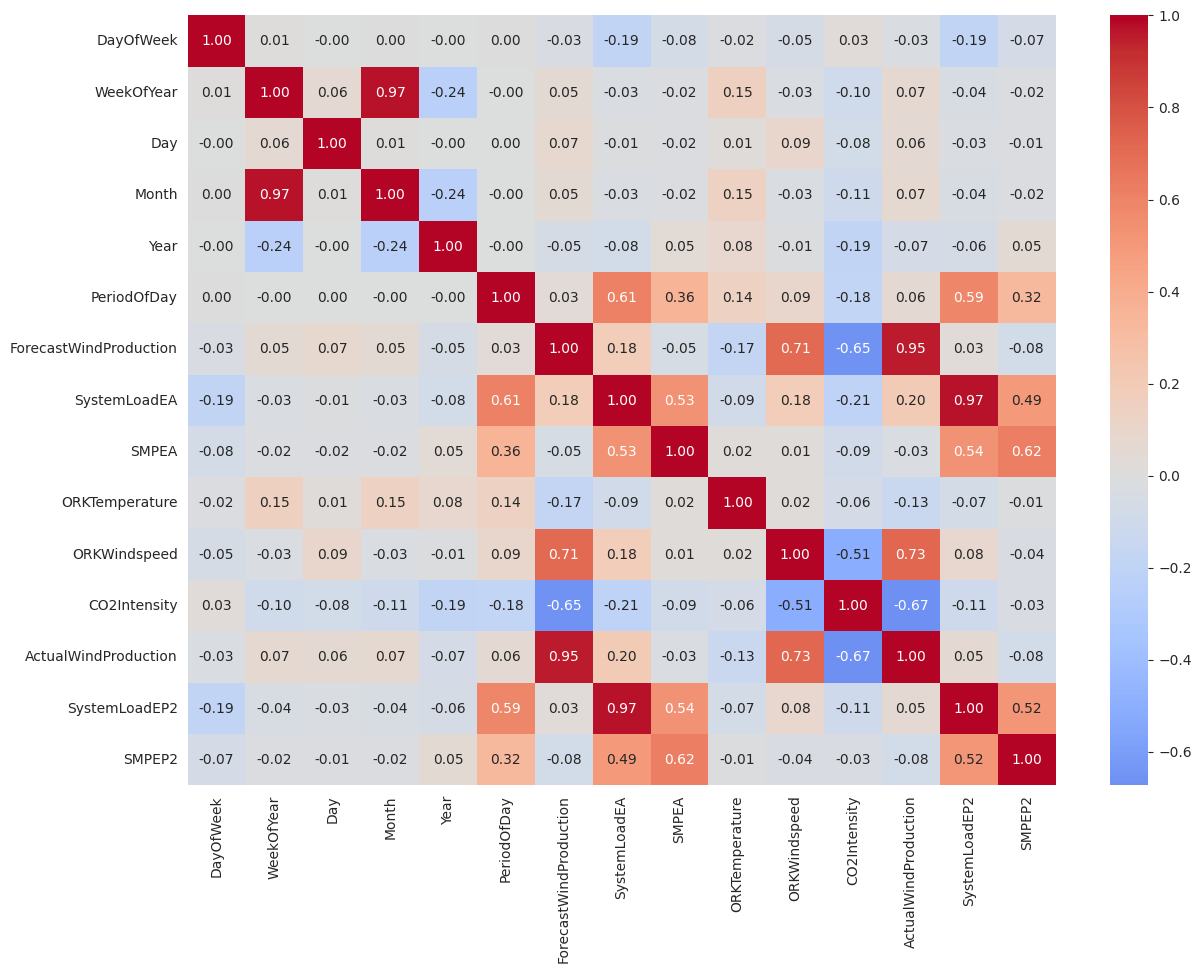

In [ ]:
# Calculate the correlation matrix excluding 'HolidayFlag'
corr_matrix = data.drop(columns=['HolidayFlag']).corr()

# Set the figure size
plt.figure(figsize=(14, 10))

# Create the heatmap with annotations (correlation values) and decimal format
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', center=0)

# Show the heatmap
plt.show()

Let's evaluate which variables show correlation, as this could negatively affect the model's prediction.

Specifically, we check for correlation between the variables x and the target y, as well as the internal decorrelation among x variables, which is the optimal state for the model.
We only consider correlations that exceed a 70% threshold:

Target:
No variable exceeds the 70% threshold.

* SystemLoadEA: 49%
* SMPEA: 62%
* SystemLoadEP2: 52%

Regarding correlation between independent variables, we reasonably observe very high correlation for the first pair of time variables and between variables representing the same phenomenon in observed and forecasted form, such as wind and production load, as follows:

* WeekOfYear and Month: 97%
* ForecastWindProduction and ORKWindSpeed: 71%
* SystemLoadEP2 and SystemLoadEA: 97%
* ForecastWindProduction and ActualWindProduction: 95%

VIF (Variance Inflation Factor)

A high VIF value (>5) indicates a problem of multicollinearity among the variables.

In [ ]:
# Select only numeric columns, excluding "HolidayFlag"
columns_to_exclude = ["HolidayFlag"]
numerical_columns = data.select_dtypes(include=['number']).columns
numerical_columns = [col for col in numerical_columns if col not in columns_to_exclude]

# Create the dataset with only independent variables
X = data[numerical_columns].copy()

# Add an intercept column (necessary for VIF calculation)
X = sm.add_constant(X)

# Calculate VIF for each variable
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print(vif_data)

                  Variable           VIF
0                    const  1.298880e+07
1                DayOfWeek  1.070164e+00
2               WeekOfYear  1.875730e+01
3                      Day  1.069335e+00
4                    Month  1.878511e+01
5                     Year  1.249498e+00
6              PeriodOfDay  1.760159e+00
7   ForecastWindProduction  1.179703e+01
8             SystemLoadEA  3.428634e+01
9                    SMPEA  1.864371e+00
10          ORKTemperature  1.240275e+00
11            ORKWindspeed  2.294018e+00
12            CO2Intensity  2.271207e+00
13    ActualWindProduction  1.292824e+01
14           SystemLoadEP2  3.167577e+01
15                  SMPEP2  1.788760e+00


Let's translate the scientific notation used for the numbers in the VIF column. The suffixes e+01, e+00 define exponential notation, and translate to the following VIF values:

'const' represents the intercept term in the model. Its VIF is normally very high because it’s a constant column.

* const  12,988,800.00
* DayOfWeek  1.07
* WeekOfYear  18.76
* Day  1.07
* Month  18.79
* Year  1.25
* PeriodOfDay  1.76
* ForecastWindProduction  11.80
* SystemLoadEA  34.29
* SMPEA  1.86
* ORKTemperature  1.24
* ORKWindspeed  2.29
* CO2Intensity  2.27
* ActualWindProduction  12.93
* SystemLoadEP2  31.68
* SMPEP2  1.79

Variables with very high multicollinearity (VIF > 10):

* SystemLoadEA (VIF ≈ 34.29)
* SystemLoadEP2 (VIF ≈ 31.68)
* ForecastWindProduction (VIF ≈ 11.80)
* ActualWindProduction (VIF ≈ 12.93)

These variables are highly collinear with others, which can cause instability issues in models.

Variables with low multicollinearity (VIF < 5):
All other variables have VIF well below the critical threshold and thus do not pose collinearity problems.

PREPROCESSING

We perform the following preprocessing steps to prepare the dataframe for modeling:

1. We conduct feature selection to reduce multicollinearity by removing, among two correlated variables, the one less correlated with the target.

2. We split the data into training and test sets, and then apply transformations separately on each set to prevent data leakage—i.e., using test set information during training, which would compromise the model’s validity.

3. We perform transformations to correct distortions related to the shape of the distribution and the presence of outliers, which could hinder the model’s ability to interpret the features.

---

FEATURE SELECTION

| Variables                                      | Correlation  | Action                                                                                                          |
| ---------------------------------------------- | ------------ | --------------------------------------------------------------------------------------------------------------- |
| SystemLoadEA vs SystemLoadEP2                  | > 0.95       | We keep SystemLoadEP2 (more correlated with SMPEP2). Additionally, SystemLoadEA has VIF ≈ 34.29.                       |
| ForecastWindProduction vs ActualWindProduction | > 0.9        | We remove ActualWindProduction. |
| ForecastWindProduction vs ORKWindspeed         | > 0.7        | We can keep both ForecastWindProduction and ORKWindspeed to better capture the weather component. |
| WeekOfYear vs Month                            | > 0.9        | We keep Month (more interpretable by models compared to WeekOfYear).                                                |

---

TRANSFORMATIONS:

1. Temporal variables

These variables must be handled with care:

| Variable        | Suggested action                                                                 |
|-----------------|-------------------------------------------------------------------------------------|
| DayOfWeek       | No transformation: already well distributed and numerical                             |
| Day             | No transformation: already well distributed and numerical                             |
| Month           | No transformation: already well distributed and numerical                             |
| Year            | No transformation: already well distributed and numerical                             |
| PeriodOfDay     | No transformation     |
| HolidayFlag     | Leave unchanged: already binary. If not informative, consider removal             |

We can apply standardization to make the variable scales comparable and facilitate their handling by the model.

2. Climatic and energy variables


| Variable                | Observation                                 | Suggested action                                               |
|-------------------------|----------------------------------------------|------------------------------------------------------------------|
| ORKTemperature          | Slightly skewed, leptokurtic, outlier            |  Yeo-Johnson                                              |
| ORKWindspeed            | Almost normal distribution, but with outliers | Yeo-Johnson for greater robustness       |
| CO2Intensity            | Symmetrical distribution but with outliers    | Standardization is sufficient                                    |
| ForecastWindProduction  | Right-skewed + outliers                       | Log transformation                         |
| SystemLoadEA            | Highly collinear with EP2, symmetrical        | Remove: keep only SystemLoadEP2                             |
| SystemLoadEP2           | Highly collinear with EA, symmetrical         | Keep: more correlated with SMPEP2. Apply standardization to reduce scale                                  |
| SMPEA                   | Skewed, with outliers                         |  Log transformation                                       |
| SMPEP2 (target)         | Skewed, clear outliers                        | Log transformation


In [ ]:
# Check if there are any problematic values in y (SMPEP2) for the LOG transformation, which is not suitable for values ≤ -1.
y = data["SMPEP2"]
min_y = y.min()
print("Minimum value in y (SMPEP2):", min_y)

# Count how many values are ≤ -1 (not suitable for log1p)
num_valori_problematici = (y <= -1).sum()
print(f"Number of values in y ≤ -1: {num_valori_problematici}")

# Show the values if any exist
if num_valori_problematici > 0:
    print("Problematic values found:")
    print(y[y <= -1])
else:
    print("No values ≤ -1 found in y.")

Minimum value in y (SMPEP2): -47.74
Number of values in y ≤ -1: 3
Problematic values found:
3131    -47.74
19872    -3.50
19877    -3.50
Name: SMPEP2, dtype: float64


We remove only the 3 problematic rows for SMPEP2 before applying the logarithmic transformation.

In [ ]:
# Removal of rows with SMPEP2 values ≤ -1
data = data[data['SMPEP2'] > -1].copy()

# Post-removal check
print("Remaining rows after removal:", data.shape[0])
print("Minimum value in y (SMPEP2) after removal:", data['SMPEP2'].min())

Remaining rows after removal: 38011
Minimum value in y (SMPEP2) after removal: 0.0


In [ ]:
# Remove columns before the split
drop_cols = ["SystemLoadEA", "ForecastWindProduction", "ActualWindProduction", "HolidayFlag", "WeekOfYear"]
data_cleaned = data.drop(columns=drop_cols)

# Define variables by type of transformation
columns_log = ["SMPEA"]
columns_yeo = ["ORKTemperature", "ORKWindspeed"]

# Columns to standardize (environmental, temporal, and load variables)
columns_std = [
    "CO2Intensity",         # environmental
    "SystemLoadEP2",        # load
    "DayOfWeek", "Day",     # temporal
    "Month", "Year", "PeriodOfDay"
]

# Columns to keep (all selected ones)
keep_columns = columns_log + columns_yeo + columns_std

# Features and target
x = data_cleaned[keep_columns]
y = data_cleaned["SMPEP2"]

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# === TRANSFORMATIONS ===

# Log transformation
x_train[columns_log] = np.log1p(x_train[columns_log])
x_test[columns_log] = np.log1p(x_test[columns_log])

# Yeo-Johnson transformation
pt = PowerTransformer(method='yeo-johnson')
x_train[columns_yeo] = pt.fit_transform(x_train[columns_yeo])
x_test[columns_yeo] = pt.transform(x_test[columns_yeo])

# StandardScaler
scaler = StandardScaler()
x_train[columns_std] = scaler.fit_transform(x_train[columns_std])
x_test[columns_std] = scaler.transform(x_test[columns_std])

# Log transform target
y_train = np.log1p(y_train)
y_test = np.log1p(y_test)

# Check
print("First rows of x_train:")
print(x_train.head())
print("\nFirst rows of x_test:")
print(x_test.head())
print("\nFirst rows of y_train:")
print(y_train.head())

First rows of x_train:
          SMPEA  ORKTemperature  ORKWindspeed  CO2Intensity  SystemLoadEP2  \
3965   4.034241       -0.100260      0.771934     -0.032898       0.154811   
2855   4.004420        0.342689      0.428413     -0.416538       0.619805   
6627   3.864722       -1.285325     -0.359542      1.061058      -1.010075   
7846   4.519503        0.122908      0.054397      0.590914       0.959312   
29739  4.065259        2.991596     -0.579626      0.431503       0.391620   

       DayOfWeek       Day     Month      Year  PeriodOfDay  
3965    1.497710  0.710195 -1.651603 -0.613413     0.396977  
2855    0.497724  1.618107  1.425688 -2.213539    -0.036517  
6627    1.497710  0.256239 -1.092096 -0.613413    -1.481496  
7846   -0.002269 -0.424696 -0.812342 -0.613413     0.035732  
29739   0.497724 -0.424696  0.026919  0.986713     0.396977  

First rows of x_test:
          SMPEA  ORKTemperature  ORKWindspeed  CO2Intensity  SystemLoadEP2  \
19735  3.577110       -0.794604    

We run Pearson correlation again after the transformations to verify the previously observed relationships.

In particular, we assess whether there is an improvement in the correlation between independent variables and the dependent variable, as well as in the internal decorrelation among independent variables.

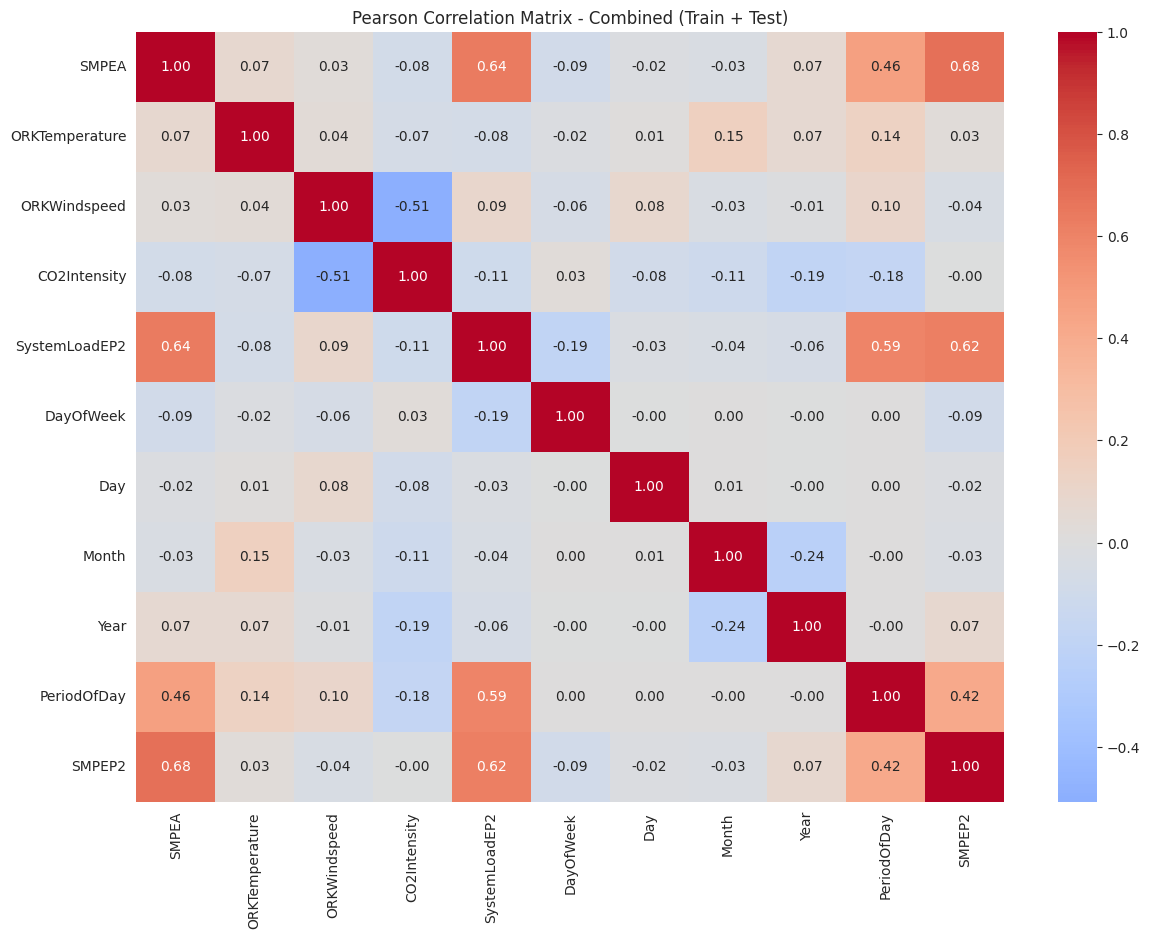

In [ ]:
# Combine x_train and x_test (features) and y_train and y_test (target)
full_df = pd.concat([x_train, x_test], axis=0)
full_df['SMPEP2'] = pd.concat([y_train, y_test], axis=0)

# Function to calculate and display Pearson correlation heatmap
def plot_pearson_correlation(df, title="Correlation matrix (Pearson)"):
    corr_matrix = df.corr(method='pearson')
    plt.figure(figsize=(14, 10))
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', center=0)
    plt.title(title)
    plt.show()

# Apply Pearson on the entire combined dataset (train + test)
plot_pearson_correlation(full_df, title="Pearson Correlation Matrix - Combined (Train + Test)")

The plot largely shows clear positions, meaning low correlation, between pairs of x variables (except for the diagonal, which identifies the variable’s identity with itself).

Regarding the correlation between the x variables and the target y:

* SMPEA: increased from 62% to 68%
* SystemLoadEP2: increased from 52% to 62%

Removing some variables seems to have improved the informative contribution of the features useful for predicting the target.

In particular, removing the variable SystemLoadEA — although moderately correlated with the target (about 49%) — significantly helped reduce multicollinearity, as it had the highest VIF among all variables (about 34.29).

BUILDING THE MODEL

In [ ]:
# Creation and training of the Random Forest model for regression
rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42)
rf_regressor.fit(x_train, y_train)

# Predictions on the test data
y_pred = rf_regressor.predict(x_test)

# Calculation of evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Print the results
print("Mean Squared Error (MSE):", mse)
print("R-squared (R2):", r2)

# Example of predictions
print("\nFirst 5 predictions vs actual values:")
for real, pred in zip(y_test.head(), y_pred[:5]):
    print(f"Actual: {real:.4f}, Predicted: {pred:.4f}")

Mean Squared Error (MSE): 0.03699098663035826
R-squared (R2): 0.7782391873551641

First 5 predictions vs actual values:
Actual: 3.6447, Predicted: 3.6395
Actual: 3.9002, Predicted: 3.8858
Actual: 5.1237, Predicted: 4.6053
Actual: 3.7908, Predicted: 3.8234
Actual: 4.8593, Predicted: 4.7583


The Mean Squared Error (MSE) of 0.037 indicates that the model has a relatively low prediction error. An R-squared (R²) value around 78% shows that the model explains a good portion of the data variability, demonstrating solid fitting capability, although there is room for improvement to further reduce the error.

To increase the R-squared value, we try an ensemble model based on Gradient Boosting, which may achieve better results than Random Forest.

We then proceed to use a Gradient Boosting Regressor model and observe its performance.

Mean Squared Error (MSE): 0.06633985869803226
R-squared (R2): 0.6022928200691591

First 5 predictions vs actual values:
Actual: 3.6447, Predicted: 3.6867
Actual: 3.9002, Predicted: 3.7629
Actual: 5.1237, Predicted: 4.7843
Actual: 3.7908, Predicted: 3.8047
Actual: 4.8593, Predicted: 4.6090


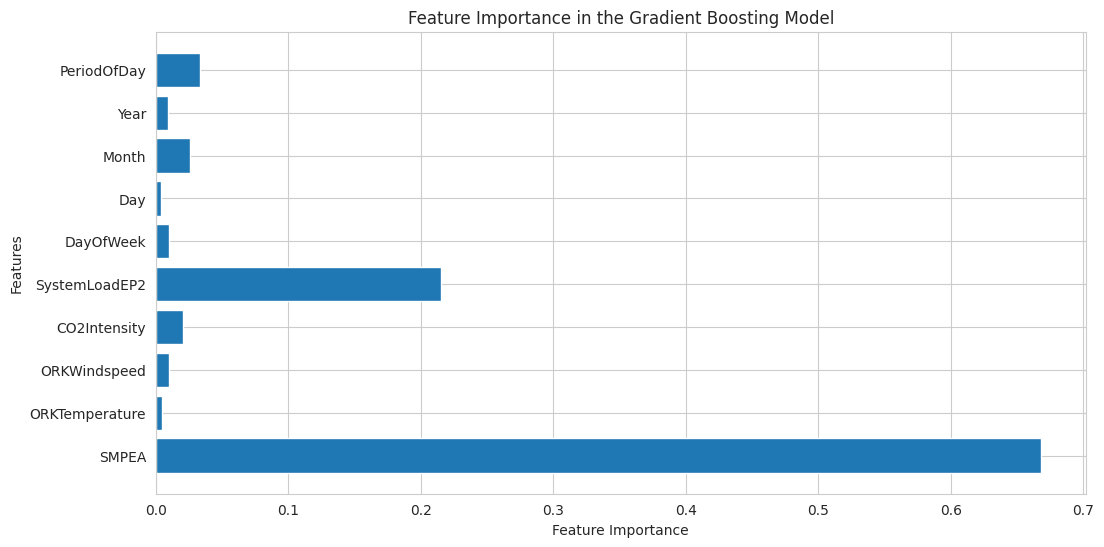

In [ ]:
# Creation and training of the Gradient Boosting Regressor model
gb_regressor = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_regressor.fit(x_train, y_train)

# Predictions on the test data
y_pred = gb_regressor.predict(x_test)

# Calculation of evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Printing the results
print("Mean Squared Error (MSE):", mse)
print("R-squared (R2):", r2)

# Example of predictions
print("\nFirst 5 predictions vs actual values:")
for real, pred in zip(y_test.head(), y_pred[:5]):
    print(f"Actual: {real:.4f}, Predicted: {pred:.4f}")

# Visualization of feature importance
importances = gb_regressor.feature_importances_
plt.figure(figsize=(12, 6))
plt.barh(x_train.columns, importances)
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Feature Importance in the Gradient Boosting Model')
plt.show()

The model returns a lower R-Squared value and a consequent loss of efficiency. At this point, we include a deeper analysis to understand which variables have contributed most to the prediction of the target variable y. Reasonably, these are the predicted price SMPEA, directly connected to the target Actual Energy Price SMPEP2, and the actual load of the national system SystemLoadEP2.

Since the variables operate as a "team," they all work in coordination and should not be considered individually: the predictive result is achieved thanks to the interconnections among them. For this reason, it is advisable to keep the current setup intact.

We then test a Linear Regression model with Ridge Regularization (for which we have already properly preprocessed the variables to have compatible scales).

In [ ]:
# RIDGE Regression
ridge = Ridge(alpha=1.0, random_state=42)
ridge.fit(x_train, y_train)
y_pred_ridge = ridge.predict(x_test)

print("\nRIDGE Regression:")
print("MSE:", mean_squared_error(y_test, y_pred_ridge))
print("R2:", r2_score(y_test, y_pred_ridge))


RIDGE Regression:
MSE: 0.07865192608760675
R2: 0.5284820267282414


R-squared value around 53%, again lower than the more efficient model. Let's try SVM (Support Vector Regression) with an RBF kernel, useful when dealing with large amounts of data and to better capture their nonlinear complexity.

In [ ]:
# Creation and training of the SVR model
svr_model = SVR(kernel='rbf', C=100, epsilon=0.1)
svr_model.fit(x_train, y_train)

# Predictions
y_pred_svr = svr_model.predict(x_test)

# Evaluation
print("SVR - Support Vector Regression:")
print("MSE:", mean_squared_error(y_test, y_pred_svr))
print("R2:", r2_score(y_test, y_pred_svr))

SVR - Support Vector Regression:
MSE: 0.05763930724328083
R2: 0.6544525902408584


R-squared value of 65% is still less effective compared to the best performing model so far.

We therefore decide to use RandomForest, the most performant model until now, integrating a GridSearchCV technique, useful to systematically improve the model’s performance.

GridSearch aims to optimize hyperparameters by running and evaluating a predefined grid of combinations via cross-validation. It returns the model with the best settings based on the R² metric.

In [ ]:
import warnings

# Disable all warnings
warnings.filterwarnings('ignore')

# Define a dictionary with hyperparameters and their values to test
# This allows exploring various combinations to find the best one
param_dist = {
    'n_estimators': [100, 200, 300, 400],            # Number of trees in the forest; more trees improve stability
    'max_depth': [10, 15, 20, 25],                   # Maximum depth of each tree; limits overfitting by controlling model complexity
    'min_samples_split': [2, 5, 10],                 # Minimum number of samples required to split a node; prevents splits with too few samples
    'min_samples_leaf': [1, 2, 4],                   # Minimum number of samples required in a leaf; improves generalization by reducing overfitting
    'max_features': ['sqrt', 'log2'],                # Number of features to consider for best split; 'sqrt' means square root of total
    'bootstrap': [True, False]                       # Options to use bootstrap sampling or not: bootstrap sampling (sampling with replacement) to build each tree increases robustness
}

# Create the base Random Forest model with fixed random_state for reproducibility
rf = RandomForestRegressor(random_state=42)

# Set up RandomizedSearchCV to perform random hyperparameter search
# n_iter indicates how many combinations to test (20 to balance time and coverage)
# cv=5 for 5-fold cross-validation, so the model internally validates on 5 different parts
# scoring='r2' means optimizing the coefficient of determination based on R2
# n_jobs=-1 uses all available cores to speed up the search
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    error_score='raise'
)

# Start hyperparameter search using training data
random_search.fit(x_train, y_train)

# Print the best parameters found by the search
print("Best parameters:", random_search.best_params_)

# Retrieve the best obtained model
best_rf = random_search.best_estimator_

# Make predictions on the test set using the best model
y_pred = best_rf.predict(x_test)

# Import metrics to evaluate the model
from sklearn.metrics import r2_score, mean_squared_error

# Calculate and print the coefficient of determination R2, a measure of model goodness
print("R2 score:", r2_score(y_test, y_pred))

# Calculate and print mean squared error, a measure of average squared absolute error
print("MSE:", mean_squared_error(y_test, y_pred))


Best parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20, 'bootstrap': False}
R2 score: 0.803735770107827
MSE: 0.03273800910707472


**Model Considerations**

The Random Forest regression model, optimized via GridSearch, demonstrated a good fit to the data, managing to predict energy price formation with an accuracy exceeding 80%.

To further refine the estimate of price variability and understand its probabilistic range, we use Monte Carlo simulations, which allow estimating the expected price value by analyzing 10,000 different scenarios of variable combinations. This method enables capturing the entire range of price variability in relation to the different influencing conditions.

**Probabilistic Forecast of Energy Price Using Monte Carlo Simulation**

This code performs a Monte Carlo simulation to estimate the behavior of the electricity price (SMPEP2), generating 10,000 random scenarios consistent with the features of the Random Forest model. Each scenario is constructed by sampling values from the distributions of the input variables (e.g., system load, weather, day of the week as weekday or holiday, time of day). The already trained model is then used to predict the price for each scenario. The results are analyzed through a histogram of the predicted price distribution and the calculation of quantiles (5%, 25%, 50%, 75%, 95%) to identify the range of price variability.

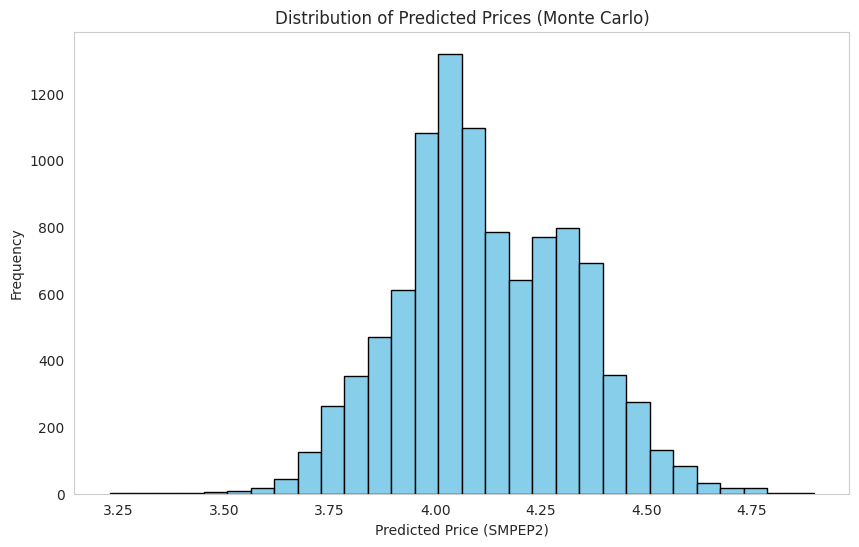

Predicted price ranges (quantiles):
5%: 3.7899
25%: 3.9859
50%: 4.0974
75%: 4.2794
95%: 4.4601


In [ ]:
# Number of simulations
n_simulations = 10000

# === Building input scenario ===
# Variables consistent with those used in the Random Forest model
scenario_df = pd.DataFrame({
    'SMPEA': np.random.normal(loc=x_train['SMPEA'].mean(), scale=x_train['SMPEA'].std(), size=n_simulations),
    'ORKTemperature': np.random.normal(loc=x_train['ORKTemperature'].mean(), scale=x_train['ORKTemperature'].std(), size=n_simulations),
    'ORKWindspeed': np.random.normal(loc=x_train['ORKWindspeed'].mean(), scale=x_train['ORKWindspeed'].std(), size=n_simulations),
    'CO2Intensity': np.random.normal(loc=x_train['CO2Intensity'].mean(), scale=x_train['CO2Intensity'].std(), size=n_simulations),
    'SystemLoadEP2': np.random.normal(loc=x_train['SystemLoadEP2'].mean(), scale=x_train['SystemLoadEP2'].std(), size=n_simulations),
    'DayOfWeek': np.random.randint(0, 7, size=n_simulations),
    'Day': np.random.randint(1, 32, size=n_simulations),
    'Month': np.random.randint(1, 13, size=n_simulations),
    'Year': 2025,  # Fixed value to maintain temporal consistency
    'PeriodOfDay': np.random.randint(0, 48, size=n_simulations),
})

# === 2. PREDICTIONS WITH THE TRAINED MODEL ===
# Use the optimized Random Forest model to predict prices for each simulated scenario
y_scenario_pred = best_rf.predict(scenario_df)

# === 3. ANALYSIS OF RESULTS ===

# Histogram of simulation results
plt.figure(figsize=(10, 6))
plt.hist(y_scenario_pred, bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Predicted Prices (Monte Carlo)')
plt.xlabel('Predicted Price (SMPEP2)')
plt.ylabel('Frequency')
plt.grid()
plt.show()

# Calculation of quantiles for price range analysis
quantiles = np.percentile(y_scenario_pred, [5, 25, 50, 75, 95])
print("Predicted price ranges (quantiles):")
for q, v in zip(['5%', '25%', '50%', '75%', '95%'], quantiles):
    print(f"{q}: {v:.4f}")

* X-axis - Predicted Price (SMPEP2):
  The X-axis represents the intervals of the predicted SMPEP2 price generated by the model. Values are divided into continuous bins, for example from 3.6 to 3.7, from 3.7 to 3.8, and so on.
  Monte Carlo simulations are based on generating *n\_simulations* different scenarios, each with a distinct combination of input variables. For each scenario, the model returns a predicted price value. The result is an array of *n\_simulations* predicted values used to build the histogram.

* Y-axis - Frequency:
  The Y-axis indicates the frequency, i.e., how many times a certain price interval occurred in the simulations.
  For example, if the price interval between 4.0 and 4.1 has a frequency of 90, it means that in 90 simulations out of *n\_simulations*, the predicted price fell within that range.

In summary, the different combinations of simulated inputs are responsible for the variations in the predicted prices.

**CONCLUSIONS**

The developed model combines machine learning techniques (Random Forest) with Monte Carlo simulation to provide probabilistic forecasts of electricity prices. The Monte Carlo simulation allowed generating realistic scenarios and containing price variability within limits consistent with historical trends, avoiding extreme fluctuations. The result is a robust predictive system capable of supporting strategic decisions in the energy market, taking into account the uncertainty related to environmental factors and demand.